In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
df = pd.read_csv("./course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data Prep

In [48]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [49]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

imputing missing values

In [50]:
categoricals = df.dtypes[df.dtypes == 'str'].index.tolist()
numericals = df.dtypes[df.dtypes != 'str'].index.tolist()
numericals.remove('converted')

for c in categoricals:
    df[c] = df[c].fillna('NA')

for n in numericals:
    df[n] = df[n].fillna(0)

splitting the data

In [51]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

Q1 - ROC AUC feature importance

In [52]:
from sklearn.metrics import roc_auc_score
for n in numericals:
    auc = roc_auc_score(df_train['converted'], df_train[n])
    print(f"{n}: {abs(auc):.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


Q2 - training the model

In [53]:
# one hot encoding
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categoricals + numericals].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)
y_train = df_train['converted'].values

val_dicts = df_val[categoricals + numericals].to_dict(orient='records')
X_val = dv.transform(val_dicts)
y_val = df_val['converted'].values

In [54]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)

In [55]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_val, y_pred[:, 1])
round(auc, 3)

0.732

Q3 - Precision & Recall

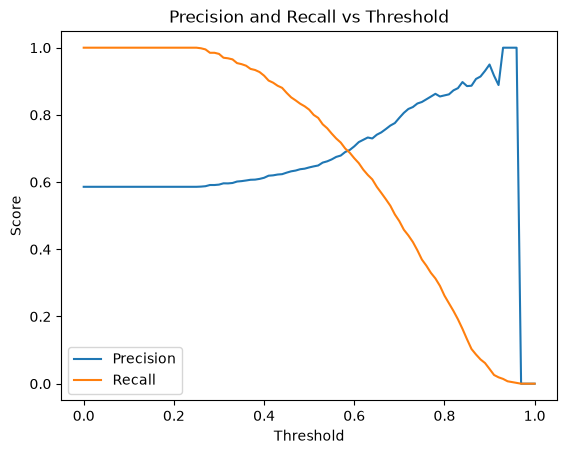

In [56]:

thresholds = np.linspace(0, 1, 101)
precisions = []
recalls = []
F1_scores = []
for t in thresholds:
    churn = (y_pred[:, 1] >= t).astype(int)
    tp = ((y_val == 1) & (churn == 1)).sum()
    fp = ((y_val == 0) & (churn == 1)).sum()
    tn = ((y_val == 1) & (churn == 0)).sum()
    fn = ((y_val == 0) & (churn == 0)).sum()

    precision = tp /(tp + fp) if (tp + fp) > 0 else 0
    recall = tp /(tp + fn) if (tp + fn) > 0 else 0
    F1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    precisions.append(precision)
    recalls.append(recall)
    F1_scores.append(F1)

# plot
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()

Q4 - F1 score

Text(0.5, 1.0, 'F1 Score vs Threshold')

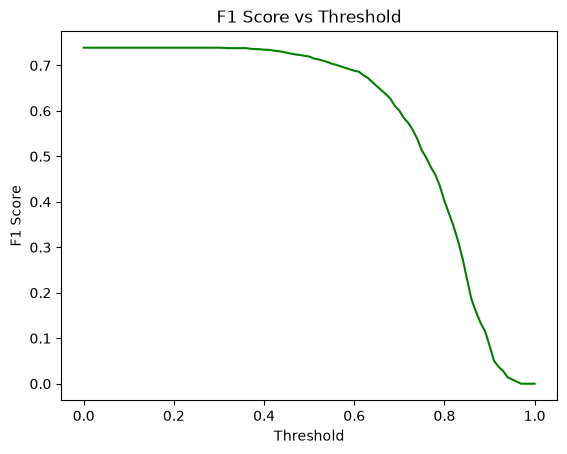

In [57]:
plt.plot(thresholds, F1_scores, label='F1 Score', color='green')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')

Q5 - 5-Fold CV

In [58]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

auc_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    train_dicts = df_train[categoricals + numericals].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)
    y_train = df_train['converted'].values

    val_dicts = df_val[categoricals + numericals].to_dict(orient='records')
    X_val = dv.transform(val_dicts)
    y_val = df_val['converted'].values

    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)

    auc = roc_auc_score(y_val, y_pred[:, 1])
    auc_scores.append(auc)
    print(f"AUC: {auc:.3f}")

print(f"Mean AUC: {np.mean(auc_scores):.3f}, Std AUC: {np.std(auc_scores):.3f}")

AUC: 0.731
AUC: 0.730
AUC: 0.736
AUC: 0.741
AUC: 0.721
Mean AUC: 0.732, Std AUC: 0.007


Q6 - Hyperparameter tuning

In [59]:
for C in [0.000001, 0.001, 1]:
    print(f"Testing C = {C}")
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)

    auc_scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        train_dicts = df_train[categoricals + numericals].to_dict(orient='records')
        X_train = dv.fit_transform(train_dicts)
        y_train = df_train['converted'].values

        val_dicts = df_val[categoricals + numericals].to_dict(orient='records')
        X_val = dv.transform(val_dicts)
        y_val = df_val['converted'].values

        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)

        auc = roc_auc_score(y_val, y_pred[:, 1])
        auc_scores.append(auc)
    print(f"Mean AUC: {np.mean(auc_scores):.3f}, Std AUC: {np.std(auc_scores):.3f}")
    print("-" * 30)

Testing C = 1e-06


Mean AUC: 0.617, Std AUC: 0.019
------------------------------
Testing C = 0.001
Mean AUC: 0.749, Std AUC: 0.010
------------------------------
Testing C = 1
Mean AUC: 0.732, Std AUC: 0.007
------------------------------
